# Telco Customer Churn

**Goal:** rank customers by churn risk so a limited retention budget goes to the customers most likely to leave.

1. Load, clean and split
2. Exploratory data analysis
3. Correlation checks
4. Hypothesis tests
5. Evaluation metrics
6. Feature engineering
7. Baseline vs. other models
8. Post-hoc model comparison
9. Final model: calibration, threshold, test results
10. SHAP and permutation importance
11. Conclusions

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
from scipy import stats
from scipy.stats import loguniform, randint, uniform

from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score, brier_score_loss, f1_score,
                             precision_recall_curve, precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import (RandomizedSearchCV, RepeatedStratifiedKFold, StratifiedKFold,
                                     cross_val_predict, cross_validate, train_test_split)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

SEED = 42
BLUE, ORANGE, GREEN, GREY = '#2a78d6', '#eb6834', '#1baf7a', '#52514e'
sns.set_theme(style='whitegrid', palette=[BLUE, ORANGE, GREEN])

## 1. Load, clean and split

- `customerID` is an identifier, so it is dropped.
- `TotalCharges` is stored as text because 11 rows are blank. All of them have `tenure = 0` (never billed), so they are set to 0.
- `SeniorCitizen` is recoded from 0/1 to No/Yes to match the other binary columns.

In [2]:
df = pd.read_csv('Telco-Customer-Churn.csv').drop(columns='customerID')
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce').fillna(0.0)
df['SeniorCitizen'] = df['SeniorCitizen'].map({0: 'No', 1: 'Yes'})
df['Churn'] = (df['Churn'] == 'Yes').astype(int)

NUM = ['tenure', 'MonthlyCharges', 'TotalCharges']
CAT = [c for c in df.columns if c not in NUM + ['Churn']]
print(df.shape)
df.head()

(7043, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,No,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,No,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


The test set is split off **before** exploration. All analysis and model choices below use the training set only, and the test set is used once at the end.

In [3]:
X, y = df.drop(columns='Churn'), df['Churn']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
train = X_train.assign(Churn=y_train)
print(f'Train: {len(X_train):,} | Test: {len(X_test):,} | Churn rate: {y_train.mean():.1%}')

Train: 5,634 | Test: 1,409 | Churn rate: 26.5%


## 2. Exploratory data analysis
### 2.1 Numeric features by churn status

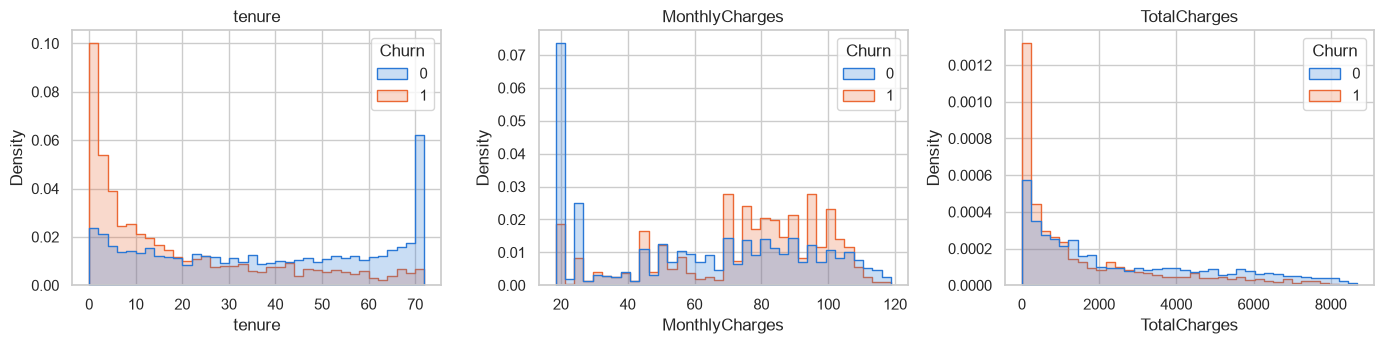

,tenure,MonthlyCharges,TotalCharges
Churn,,,
0,38.0,64.40,1686.15
1,10.0,79.95,740.30


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for col, ax in zip(NUM, axes):
    sns.histplot(data=train, x=col, hue='Churn', stat='density', common_norm=False, bins=36,
                 element='step', alpha=0.25, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

train.groupby('Churn')[NUM].median()

- **tenure** separates the classes best. Churn is concentrated in the first months (median about 10 months for churners vs. 38 for stayers).
- **MonthlyCharges** is higher for churners, especially at $70–$105 (fibre-optic plans).
- **TotalCharges** is skewed and closely tracks tenure (Section 3).

About **1 in 4** customers churns, so a model that always predicts "no churn" is already about 73% accurate. This is why accuracy is not used (Section 5).

### 2.2 Churn rate by category

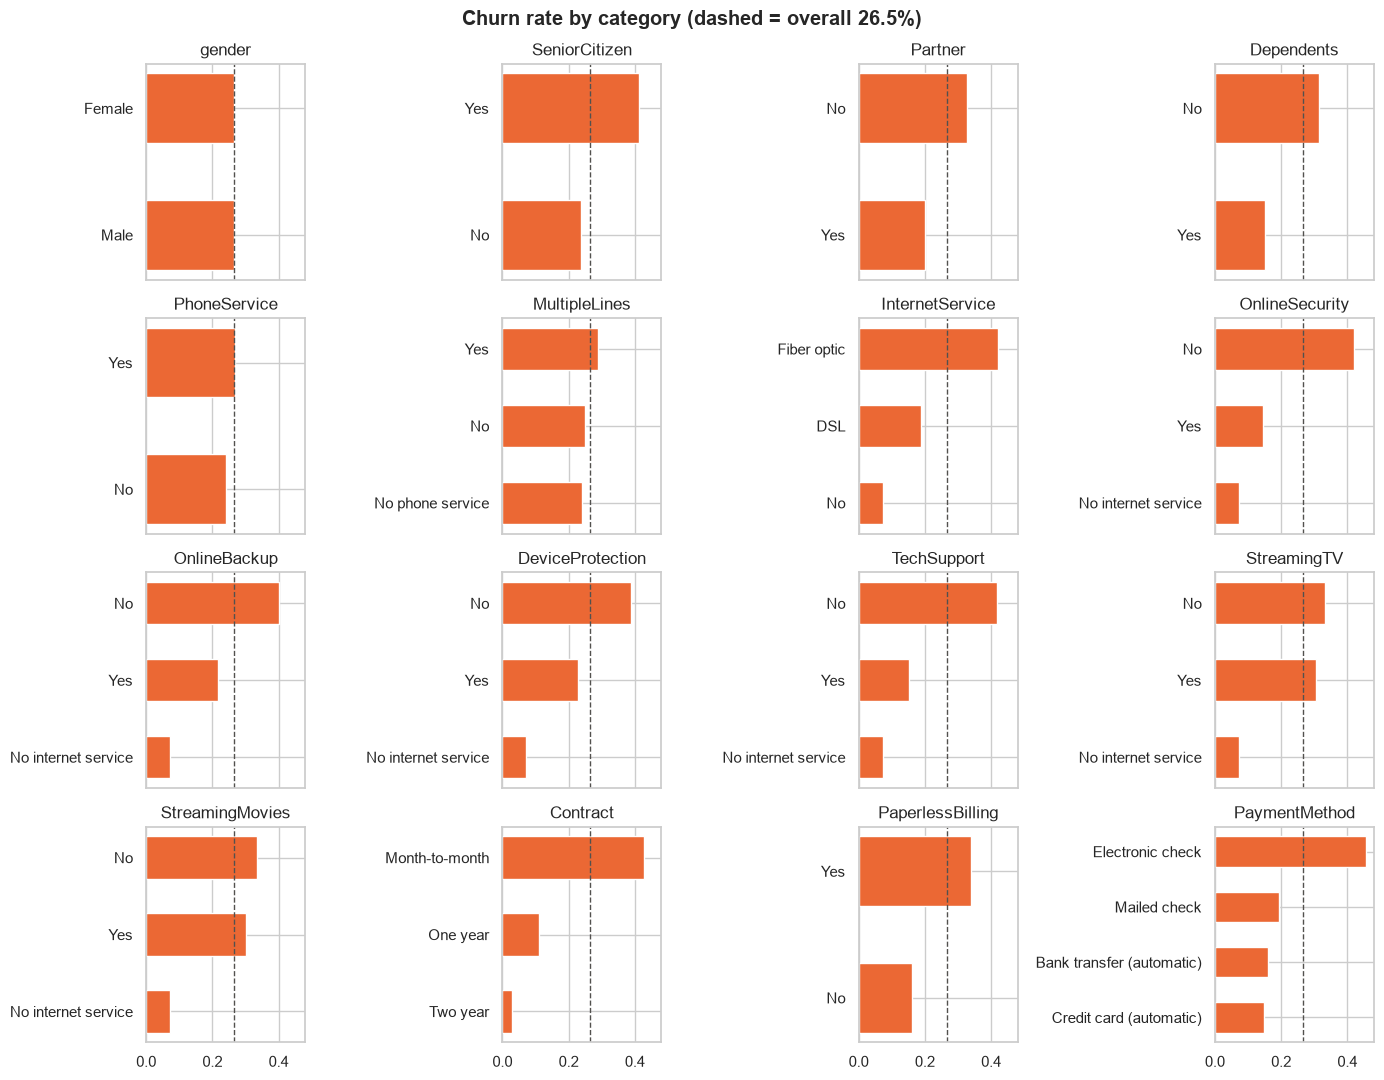

In [5]:
rate = y_train.mean()
fig, axes = plt.subplots(4, 4, figsize=(14, 11), sharex=True)
for col, ax in zip(CAT, axes.flat):
    rates = train.groupby(col)['Churn'].mean().sort_values()
    ax.barh(rates.index, rates.values, color=ORANGE, height=0.55)
    ax.axvline(rate, color=GREY, ls='--', lw=1)
    ax.set_title(col)
fig.suptitle(f'Churn rate by category (dashed = overall {rate:.1%})', fontweight='bold')
plt.tight_layout()
plt.show()

- **Contract** has the widest spread: about 43% churn on month-to-month vs. about 3% on two-year contracts.
- **Fibre optic**, **electronic check** and **paperless billing** have above-average churn. **OnlineSecurity** and **TechSupport** go with lower churn.
- **gender** and **PhoneService** sit at the overall rate and look uninformative.
- "No internet service" has the same churn rate in all six add-on columns. It is the same customers each time (`InternetService = No`), so these levels are redundant.

### 2.3 Contract vs. tenure
Long-tenure customers tend to have long contracts, so the contract effect could just be tenure. Comparing contracts within tenure bands checks this.

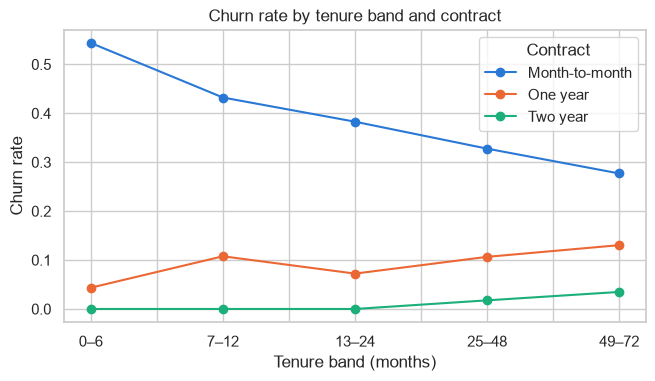

In [6]:
bands = pd.cut(train['tenure'], bins=[-1, 6, 12, 24, 48, 72], labels=['0–6', '7–12', '13–24', '25–48', '49–72'])
train.groupby([bands, 'Contract'], observed=True)['Churn'].mean().unstack().plot(marker='o', figsize=(7.5, 3.8))
plt.xlabel('Tenure band (months)')
plt.ylabel('Churn rate')
plt.title('Churn rate by tenure band and contract')
plt.show()

Month-to-month customers churn more than contract customers in **every** tenure band, so contract matters beyond tenure. Within month-to-month, churn also falls with tenure.

## 3. Correlation checks
### 3.1 Numeric features (Spearman)

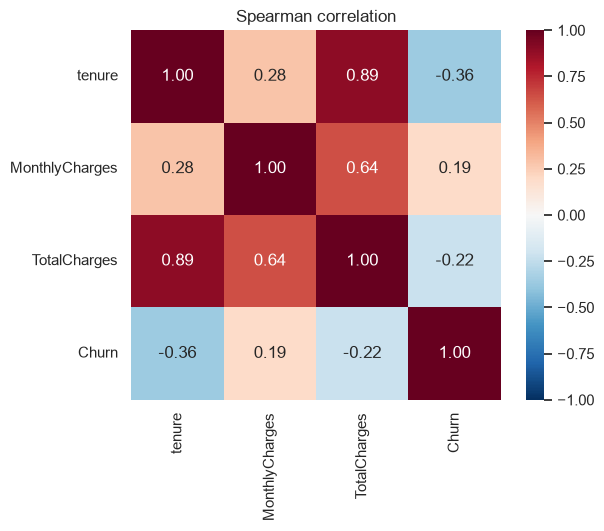

r(TotalCharges, tenure × MonthlyCharges) = 0.9996
R² of MonthlyCharges ~ services: 0.9988


In [7]:
sns.heatmap(train[NUM + ['Churn']].corr(method='spearman'), annot=True, fmt='.2f', cmap='RdBu_r',
            vmin=-1, vmax=1, square=True)
plt.title('Spearman correlation')
plt.show()

print(f'r(TotalCharges, tenure × MonthlyCharges) = {np.corrcoef(train["TotalCharges"], train["tenure"] * train["MonthlyCharges"])[0, 1]:.4f}')

SERVICES = ['PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup',
            'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
dummies = pd.get_dummies(train[SERVICES], drop_first=True)
print(f'R² of MonthlyCharges ~ services: {LinearRegression().fit(dummies, train["MonthlyCharges"]).score(dummies, train["MonthlyCharges"]):.4f}')

- `TotalCharges` is almost exactly `tenure × MonthlyCharges` (r ≈ 0.9996), so it is nearly redundant.
- The subscribed services explain **99.9%** of `MonthlyCharges`: the bill is effectively a price list applied to the service bundle. This matters when interpreting the model in Section 10.

### 3.2 Categorical features (Cramér's V)

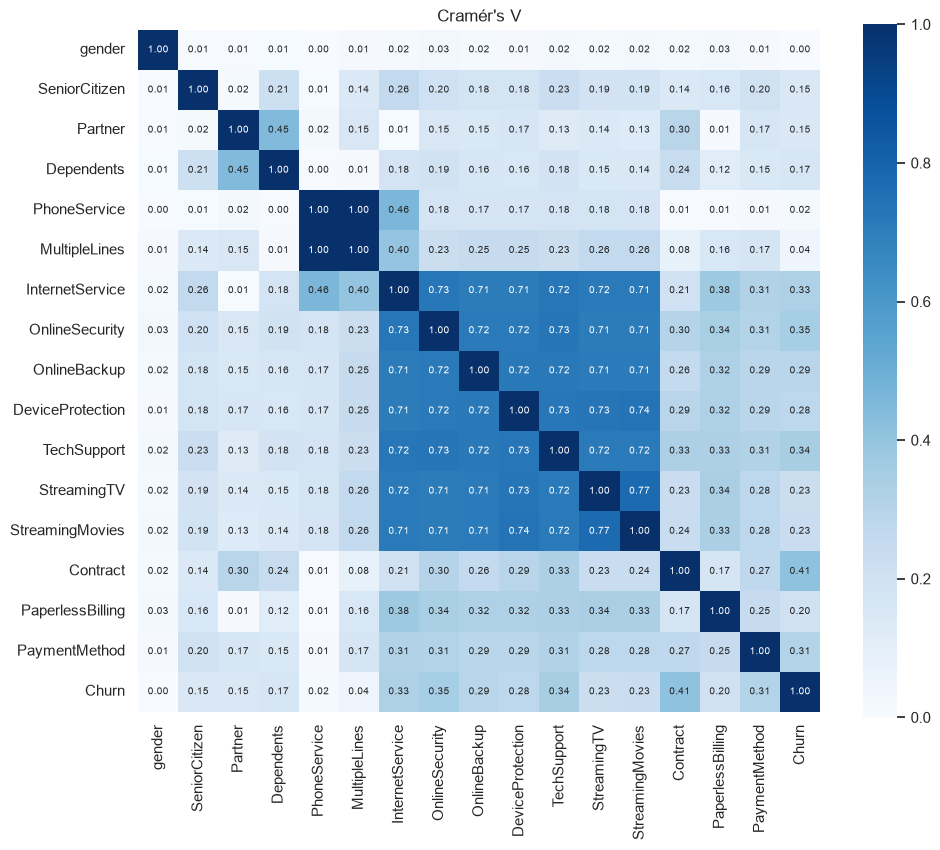

In [8]:
def cramers_v(a, b):
    table = pd.crosstab(a, b)
    chi2 = stats.chi2_contingency(table, correction=False)[0]
    return np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))

cols = CAT + ['Churn']
cv_matrix = pd.DataFrame([[cramers_v(train[a], train[b]) for b in cols] for a in cols], index=cols, columns=cols)

plt.figure(figsize=(11, 9))
sns.heatmap(cv_matrix, annot=True, fmt='.2f', cmap='Blues', vmin=0, vmax=1, square=True, annot_kws={'size': 7})
plt.title("Cramér's V")
plt.show()

- The six internet add-ons associate at about 0.7 with `InternetService` and with each other, mostly through the shared "No internet service" level. `MultipleLines` and `PhoneService` overlap completely in the same way.
- With churn, **Contract** (0.41), **OnlineSecurity**, **TechSupport**, **InternetService** and **PaymentMethod** are strongest. **gender** and **PhoneService** are about 0.

## 4. Hypothesis tests
Both tests use the training set at α = 0.05.

### H1: Is contract type associated with churn?
$H_0$: Contract and churn are independent. **Test:** χ² test of independence.

In [9]:
observed = pd.crosstab(train['Contract'], train['Churn'])
chi2, p, dof, _ = stats.chi2_contingency(observed)
print(observed)
print(f"\nchi2({dof}) = {chi2:.1f}, p = {p:.2e}, Cramér's V = {cramers_v(train['Contract'], train['Churn']):.3f}")

Churn              0     1
Contract                  
Month-to-month  1776  1326
One year        1043   130
Two year        1320    39

chi2(2) = 952.3, p = 1.62e-207, Cramér's V = 0.411


**Reject $H_0$.** Contract and churn are strongly associated (V ≈ 0.41). Month-to-month customers churn at about 15× the rate of two-year customers.

### H2: Do churners pay higher monthly charges?
$H_0$: Monthly charges have the same distribution for churners and stayers. $H_1$: churners' charges are higher. **Test:** one-sided Mann–Whitney U, because `MonthlyCharges` is not normally distributed (Section 2.1).

In [10]:
churned = train.loc[train['Churn'] == 1, 'MonthlyCharges']
retained = train.loc[train['Churn'] == 0, 'MonthlyCharges']
u, p = stats.mannwhitneyu(churned, retained, alternative='greater')
print(f'Median — churned: ${churned.median():.2f} | retained: ${retained.median():.2f}')
print(f'U = {u:,.0f}, p = {p:.2e}, P(churner pays more) = {u / (len(churned) * len(retained)):.3f}')

Median — churned: $79.95 | retained: $64.40
U = 3,860,744, p = 3.16e-46, P(churner pays more) = 0.624


**Reject $H_0$.** Churners pay more: a random churner pays more than a random stayer about 62% of the time. This is a real but modest effect, much weaker than contract or tenure.

## 5. Evaluation metrics

| Metric | Role |
|---|---|
| **PR-AUC** (average precision) | **Primary.** Measures how well churners are ranked. The no-skill baseline is the churn rate (≈0.27), so it is more informative than ROC-AUC under imbalance. |
| ROC-AUC | Secondary, standard ranking metric |
| Brier score | Checks that predicted probabilities are reliable, which the profit-based threshold depends on |
| Precision / recall / F1 | Reported at the chosen threshold |
| Expected campaign profit | Used to choose the threshold. Puts missed churners and wasted offers on one scale. |

## 6. Feature engineering

| Change | Why |
|---|---|
| Replace "No internet service" / "No phone service" with "No" | Removes the redundant levels from Section 3.2 |
| Log-transform `tenure` | Churn risk drops steeply in the first months and then levels off (Section 2.1). A linear model can only follow that curve on a log scale. |
| Drop `TotalCharges` | Nearly identical to tenure × MonthlyCharges |
| Drop `gender`, `PhoneService` | No association with churn |

The transformations run inside the model pipeline, so the pipeline accepts raw data and nothing leaks between CV folds.

### 6.1 Feature screen
Mutual information and univariate tests (χ² for categorical, Mann–Whitney for numeric) confirm which features carry no signal.

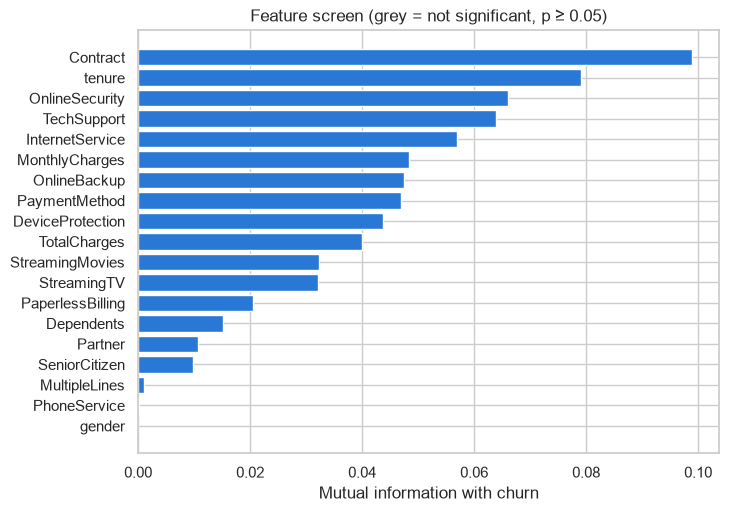

In [11]:
mi_input = X_train.apply(lambda s: s.astype('category').cat.codes if s.name in CAT else s)
mi = pd.Series(mutual_info_classif(mi_input, y_train, discrete_features=[c in CAT for c in X_train], random_state=SEED),
               index=X_train.columns)
pvals = pd.Series({c: stats.chi2_contingency(pd.crosstab(X_train[c], y_train))[1] if c in CAT
                   else stats.mannwhitneyu(X_train.loc[y_train == 1, c], X_train.loc[y_train == 0, c])[1]
                   for c in X_train})
screen = pd.DataFrame({'mutual_info': mi, 'p_value': pvals}).sort_values('mutual_info')

plt.figure(figsize=(7.5, 5.5))
plt.barh(screen.index, screen['mutual_info'], color=np.where(screen['p_value'] >= 0.05, GREY, BLUE))
plt.xlabel('Mutual information with churn')
plt.title('Feature screen (grey = not significant, p ≥ 0.05)')
plt.show()

Only `gender` and `PhoneService` are not significant (MI ≈ 0), so they are the features to drop.

### 6.2 Does each change help?
Each change is added in turn and scored with **repeated cross-validation** (5 folds × 5 repeats = 25 scores, the same folds for every row). Two probe models are used because they react differently: Logistic Regression (linear) and XGBoost (trees, which are not affected by log transforms).

In [12]:
ADDONS = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']

def make_engineer(collapse=True, log_tenure=True):
    def engineer(X):
        X = X.copy()
        if collapse:
            cols = ADDONS + ['MultipleLines']
            X[cols] = X[cols].replace({'No internet service': 'No', 'No phone service': 'No'})
        if log_tenure:
            X['tenure'] = np.log1p(X['tenure'])
        return X
    return engineer

def build_pipeline(model, num_cols, cat_cols, fe):
    prep = ColumnTransformer([
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='if_binary', handle_unknown='ignore', sparse_output=False), cat_cols),
    ], verbose_feature_names_out=False)
    return Pipeline([('fe', FunctionTransformer(fe)), ('prep', prep), ('model', model)])

CV = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)
SCORING = {'pr_auc': 'average_precision', 'roc_auc': 'roc_auc', 'brier': 'neg_brier_score'}

def cv_scores(pipe):
    s = cross_validate(pipe, X_train, y_train, cv=CV, scoring=SCORING, n_jobs=-1)
    return pd.DataFrame({'pr_auc': s['test_pr_auc'], 'roc_auc': s['test_roc_auc'], 'brier': -s['test_brier']})

CAT_SEL = [c for c in CAT if c not in ['gender', 'PhoneService']]
NUM_SEL = ['tenure', 'MonthlyCharges']
steps = {
    '0. raw features':                 (make_engineer(False, False), NUM, CAT),
    '1. collapse redundant levels':    (make_engineer(log_tenure=False), NUM, CAT),
    '2. + log(tenure)':                (make_engineer(), NUM, CAT),
    '3. − gender, PhoneService':       (make_engineer(), NUM, CAT_SEL),
    '4. − TotalCharges':               (make_engineer(), NUM_SEL, CAT_SEL),
}
probes = {'LogReg': LogisticRegression(max_iter=2000),
          'XGBoost': XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=3, random_state=SEED)}

ablation = pd.DataFrame({m: {name: cv_scores(build_pipeline(clone(model), num, cat, fe))['pr_auc'].mean()
                             for name, (fe, num, cat) in steps.items()}
                         for m, model in probes.items()})
ablation.round(4)

,LogReg,XGBoost
0. raw features,0.6605,0.6658
1. collapse redundant levels,0.6605,0.6634
2. + log(tenure),0.6733,0.6634
"3. − gender, PhoneService",0.6737,0.6634
4. − TotalCharges,0.6740,0.6628


- **Log(tenure)** is the one change that matters: Logistic Regression gains about +0.013 PR-AUC. XGBoost is unchanged, as expected for trees.
- Collapsing levels and dropping `gender`, `PhoneService` and `TotalCharges` cost nothing, so they are kept for simplicity.
- Tree models lose about 0.002–0.003 on the final set compared with raw features. That is too small to change the model comparison below.

The final feature set is **step 4**: 16 features.

In [13]:
engineer = make_engineer()
NUM_FINAL, CAT_FINAL = NUM_SEL, CAT_SEL

## 7. Baseline vs. other models

All models are scored with the same 25-fold repeated CV, so their scores can be compared fold by fold in Section 8. No resampling or class weights are used: ranking metrics do not need balanced classes, and reweighting would distort the probabilities used for the profit threshold.

### 7.1 Baselines
A **dummy** model (predicts the churn rate for everyone) and an untuned **Logistic Regression**.

In [14]:
results = {
    'Dummy': cv_scores(build_pipeline(DummyClassifier(), NUM_FINAL, CAT_FINAL, engineer)),
    'LogReg (baseline)': cv_scores(build_pipeline(LogisticRegression(max_iter=2000), NUM_FINAL, CAT_FINAL, engineer)),
}

def summarise(results):
    return pd.DataFrame({name: s.mean() for name, s in results.items()}).T.sort_values('pr_auc', ascending=False).round(4)

summarise(results)

,pr_auc,roc_auc,brier
LogReg (baseline),0.6740,0.8511,0.1326
Dummy,0.2654,0.5000,0.1949


### 7.2 Tuned candidate models
Each model is tuned with a **randomised hyperparameter search** (30 settings, 5-fold CV, optimising PR-AUC). The search uses a different split from the evaluation CV. Logistic Regression is tuned too, so the comparison is fair.

In [15]:
search_spaces = {
    'LogReg (tuned)': (LogisticRegression(max_iter=2000), {'C': loguniform(1e-3, 10)}),
    'KNN': (KNeighborsClassifier(), {'n_neighbors': randint(5, 151), 'weights': ['uniform', 'distance']}),
    'RandomForest': (RandomForestClassifier(n_estimators=400, random_state=SEED),
                     {'max_depth': [4, 6, 8, 10, 12, None], 'min_samples_leaf': randint(1, 60),
                      'max_features': ['sqrt', 0.3, 0.5]}),
    'HistGB': (HistGradientBoostingClassifier(random_state=SEED),
               {'learning_rate': loguniform(0.01, 0.3), 'max_iter': randint(100, 500),
                'max_leaf_nodes': randint(4, 48), 'min_samples_leaf': randint(10, 200),
                'l2_regularization': loguniform(1e-3, 10)}),
    'XGBoost': (XGBClassifier(random_state=SEED),
                {'n_estimators': randint(100, 600), 'learning_rate': loguniform(0.01, 0.3),
                 'max_depth': randint(2, 7), 'min_child_weight': loguniform(1, 20),
                 'subsample': uniform(0.6, 0.4), 'colsample_bytree': uniform(0.5, 0.5),
                 'reg_lambda': loguniform(0.1, 20)}),
}

best_params = {}
for name, (model, space) in search_spaces.items():
    search = RandomizedSearchCV(build_pipeline(model, NUM_FINAL, CAT_FINAL, engineer),
                                {f'model__{k}': v for k, v in space.items()}, n_iter=30,
                                scoring='average_precision', cv=StratifiedKFold(5, shuffle=True, random_state=SEED + 1),
                                random_state=SEED, n_jobs=-1)
    search.fit(X_train, y_train)
    best_params[name] = {k.removeprefix('model__'): v for k, v in search.best_params_.items()}
    results[name] = cv_scores(search.best_estimator_)

leaderboard = summarise(results)
leaderboard

,pr_auc,roc_auc,brier
LogReg (tuned),0.6743,0.8512,0.1326
LogReg (baseline),0.6740,0.8511,0.1326
XGBoost,0.6683,0.8493,0.1336
HistGB,0.6649,0.8465,0.1346
RandomForest,0.6613,0.8463,0.1348
KNN,0.6564,0.8451,0.1363
Dummy,0.2654,0.5000,0.1949


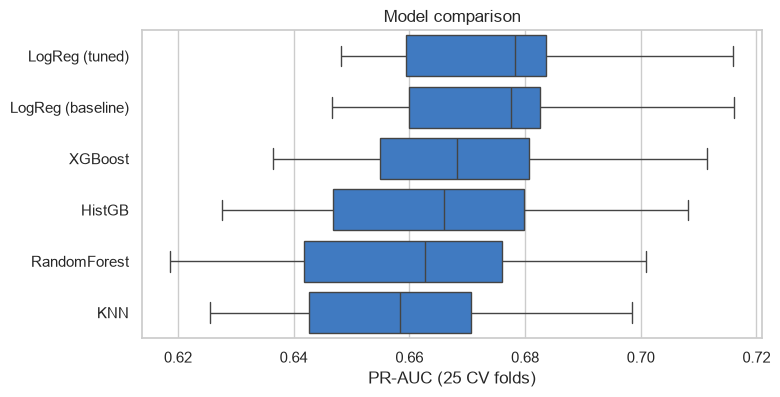

In [16]:
order = leaderboard.drop(index='Dummy').index
plt.figure(figsize=(8, 4))
sns.boxplot(data=pd.DataFrame({m: results[m]['pr_auc'] for m in order}), orient='h', color=BLUE)
plt.xlabel('PR-AUC (25 CV folds)')
plt.title('Model comparison')
plt.show()

- **Logistic Regression has the highest mean PR-AUC (≈0.674), the highest ROC-AUC and the lowest Brier score.** Tuning barely changes it.
- XGBoost and HistGB are close behind, Random Forest slightly lower, and KNN last. The Dummy model is at 0.27.
- The spread across folds (≈0.02) is larger than the gaps between models, so the next section checks whether those gaps are real.

## 8. Post-hoc comparison

1. **Friedman test:** do the models' rankings across folds differ at all?
2. **Corrected paired t-test** (Nadeau & Bengio) of the top model against each other model, with **Holm** correction for multiple comparisons. A plain paired t-test is too optimistic here, because CV folds share training data and their scores are not independent.

In [17]:
contenders = order.tolist()
fold_scores = pd.DataFrame({m: results[m]['pr_auc'].values for m in contenders})
friedman = stats.friedmanchisquare(*fold_scores.T.values)
print(f'Friedman chi2 = {friedman.statistic:.2f}, p = {friedman.pvalue:.2e}')
print(fold_scores.rank(axis=1, ascending=False).mean().sort_values().round(2).to_string())

Friedman chi2 = 74.10, p = 1.44e-14
LogReg (tuned)       1.72
LogReg (baseline)    2.12
XGBoost              3.16
HistGB               3.96
RandomForest         4.60
KNN                  5.44


In [18]:
n_test = len(X_train) // 5
n_train = len(X_train) - n_test
top = contenders[0]

rows = []
for other in contenders[1:]:
    d = fold_scores[top] - fold_scores[other]
    se = np.sqrt((1 / len(d) + n_test / n_train) * d.var(ddof=1))
    t = d.mean() / se
    half = stats.t.ppf(0.975, len(d) - 1) * se
    rows.append({'vs': other, 'diff': d.mean(), 'ci_low': d.mean() - half, 'ci_high': d.mean() + half,
                 'p': 2 * stats.t.sf(abs(t), len(d) - 1)})
posthoc = pd.DataFrame(rows).set_index('vs').sort_values('p')

# Holm: multiply the i-th smallest p-value by (m - i), then keep the sequence non-decreasing
m = len(posthoc)
posthoc['p_holm'] = np.minimum(1, np.maximum.accumulate(posthoc['p'] * np.arange(m, 0, -1)))
posthoc['significant'] = posthoc['p_holm'] < 0.05
posthoc.round(4)

,diff,ci_low,ci_high,p,p_holm,significant
vs,,,,,,
KNN,0.0179,0.0095,0.0262,0.0002,0.0009,True
RandomForest,0.0129,0.0026,0.0233,0.0167,0.0668,False
HistGB,0.0094,-0.0007,0.0195,0.0667,0.2002,False
XGBoost,0.0060,-0.0016,0.0135,0.1162,0.2323,False
LogReg (baseline),0.0003,-0.0006,0.0011,0.5003,0.5003,False


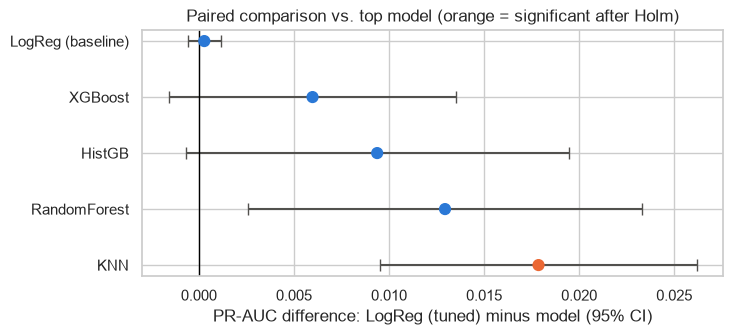

In [19]:
posthoc = posthoc.loc[contenders[1:]]
ypos = np.arange(len(posthoc))[::-1]
plt.figure(figsize=(7.5, 3.2))
plt.errorbar(posthoc['diff'], ypos, xerr=[posthoc['diff'] - posthoc['ci_low'], posthoc['ci_high'] - posthoc['diff']],
             fmt='none', ecolor=GREY, capsize=4)
plt.scatter(posthoc['diff'], ypos, s=60, zorder=3, color=np.where(posthoc['significant'], ORANGE, BLUE))
plt.axvline(0, color='black', lw=1)
plt.yticks(ypos, posthoc.index)
plt.xlabel(f'PR-AUC difference: {top} minus model (95% CI)')
plt.title('Paired comparison vs. top model (orange = significant after Holm)')
plt.show()

- **Friedman rejects** equal performance. Logistic Regression has the best mean rank.
- After Holm correction, Logistic Regression is significantly better **only than KNN**. Its leads over XGBoost, HistGB and Random Forest are **not significant**.

**Choice:** Logistic Regression and the tree ensembles are statistically tied, so the practical factors decide, and they favour **Logistic Regression**. It has the best calibration (Brier), it is the simplest model, and it is the easiest to explain. Once tenure is on a log scale, there is little non-linearity left for trees to exploit.

## 9. Final model

In [20]:
FINAL = 'LogReg (tuned)'
final_pipe = build_pipeline(LogisticRegression(max_iter=2000, **best_params[FINAL]), NUM_FINAL, CAT_FINAL, engineer)

# Out-of-fold training predictions, used for calibration and threshold choice
oof = cross_val_predict(final_pipe, X_train, y_train, cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
                        method='predict_proba')[:, 1]
final_pipe.fit(X_train, y_train)
print(best_params[FINAL])

{'C': np.float64(6.351221010640703)}


### 9.1 Calibration

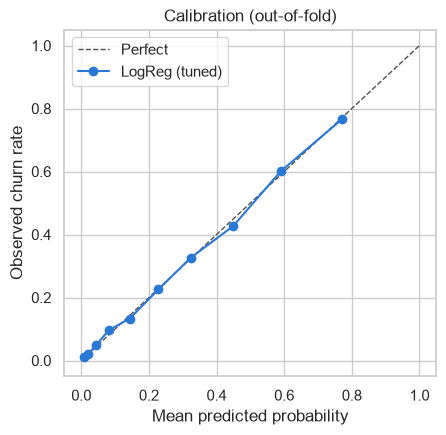

In [21]:
frac_pos, mean_pred = calibration_curve(y_train, oof, n_bins=10, strategy='quantile')
plt.figure(figsize=(4.8, 4.5))
plt.plot([0, 1], [0, 1], '--', color=GREY, lw=1, label='Perfect')
plt.plot(mean_pred, frac_pos, marker='o', color=BLUE, label=FINAL)
plt.xlabel('Mean predicted probability')
plt.ylabel('Observed churn rate')
plt.title('Calibration (out-of-fold)')
plt.legend()
plt.show()

The curve follows the diagonal, so the predicted probabilities can be read directly as churn likelihoods. No extra calibration step is needed.

### 9.2 Profit-based threshold
A simple retention model, with **illustrative assumptions** (replace with real figures):
- Each contacted customer receives an offer costing `OFFER_COST`.
- A contacted customer who would have churned is kept with probability `SAVE_RATE`.
- A kept customer is worth `HORIZON_MONTHS` × their monthly charge.

The threshold that maximises expected profit is chosen on the out-of-fold training predictions and then applied to the test set.

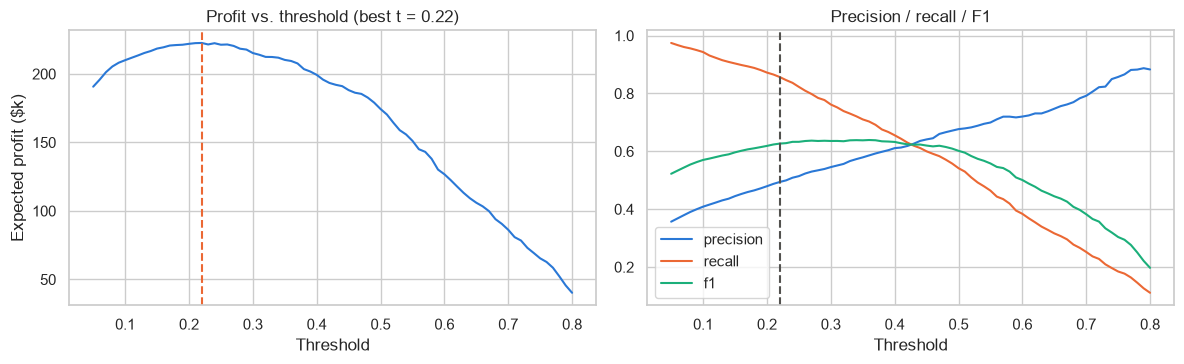

,profit,precision,recall,f1
0.22,222583.00,0.494,0.857,0.627
0.36,209431.38,0.586,0.703,0.639
0.50,174396.42,0.677,0.542,0.602


In [22]:
OFFER_COST = 50.0
SAVE_RATE = 0.30
HORIZON_MONTHS = 12

def campaign_profit(y_true, proba, monthly, t):
    target = proba >= t
    return (y_true[target] * SAVE_RATE * HORIZON_MONTHS * monthly[target]).sum() - OFFER_COST * target.sum()

thresholds = np.round(np.arange(0.05, 0.81, 0.01), 2)
curve = pd.DataFrame({
    'profit': [campaign_profit(y_train.values, oof, X_train['MonthlyCharges'].values, t) for t in thresholds],
    'precision': [precision_score(y_train, oof >= t) for t in thresholds],
    'recall': [recall_score(y_train, oof >= t) for t in thresholds],
    'f1': [f1_score(y_train, oof >= t) for t in thresholds],
}, index=thresholds)
T = curve['profit'].idxmax()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(curve.index, curve['profit'] / 1000, color=BLUE)
axes[0].axvline(T, color=ORANGE, ls='--')
axes[0].set(xlabel='Threshold', ylabel='Expected profit ($k)', title=f'Profit vs. threshold (best t = {T:.2f})')
curve[['precision', 'recall', 'f1']].plot(ax=axes[1], title='Precision / recall / F1')
axes[1].axvline(T, color=GREY, ls='--')
axes[1].set_xlabel('Threshold')
plt.tight_layout()
plt.show()

curve.loc[[T, curve['f1'].idxmax(), 0.5]].round(3)

The profit-optimal threshold (≈0.22) is well below 0.5. A missed churner costs about 0.30 × 12 × $75 ≈ $270 in expected value, more than five times a wasted $50 offer, so it pays to contact more customers. The default 0.5 would give up about 22% of the profit.

### 9.3 Test-set results
The test set is used here for the first and only time.

In [23]:
proba_test = final_pipe.predict_proba(X_test)[:, 1]
pred_test = (proba_test >= T).astype(int)

pd.Series({
    'PR-AUC': average_precision_score(y_test, proba_test),
    'ROC-AUC': roc_auc_score(y_test, proba_test),
    'Brier': brier_score_loss(y_test, proba_test),
    'Precision': precision_score(y_test, pred_test),
    'Recall': recall_score(y_test, pred_test),
    'F1': f1_score(y_test, pred_test),
    'Share contacted': pred_test.mean(),
}).round(3).to_frame('Test')

,Test
PR-AUC,0.664
ROC-AUC,0.848
Brier,0.135
Precision,0.482
Recall,0.840
F1,0.613
Share contacted,0.462


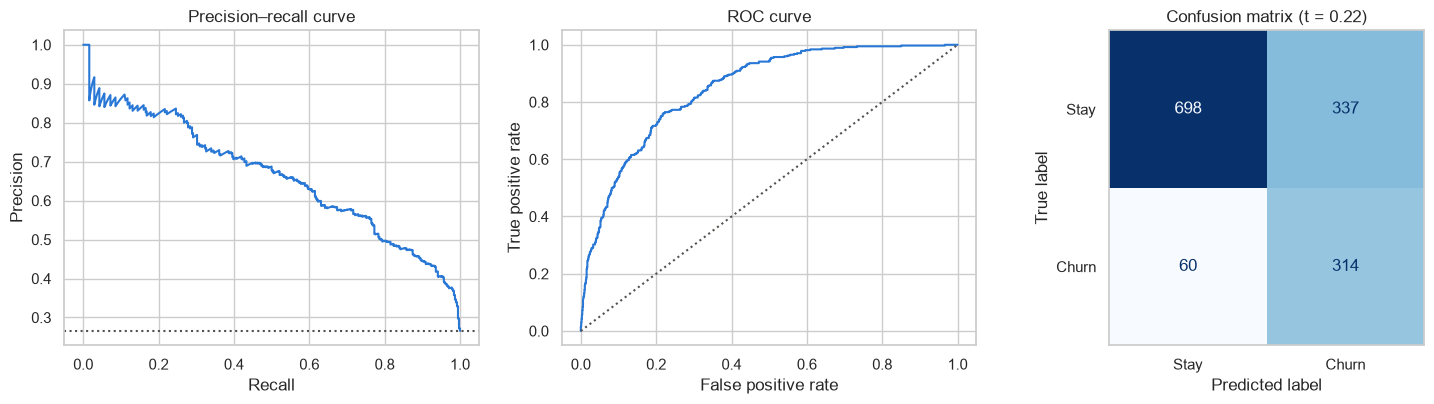

Expected profit — model (t = 0.22): $51,125
Expected profit — contact everyone:   $27,524
Expected profit — default t = 0.5:    $40,141


In [24]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
prec, rec, _ = precision_recall_curve(y_test, proba_test)
axes[0].plot(rec, prec, color=BLUE)
axes[0].axhline(y_test.mean(), color=GREY, ls=':')
axes[0].set(xlabel='Recall', ylabel='Precision', title='Precision–recall curve')
fpr, tpr, _ = roc_curve(y_test, proba_test)
axes[1].plot(fpr, tpr, color=BLUE)
axes[1].plot([0, 1], [0, 1], color=GREY, ls=':')
axes[1].set(xlabel='False positive rate', ylabel='True positive rate', title='ROC curve')
ConfusionMatrixDisplay.from_predictions(y_test, pred_test, display_labels=['Stay', 'Churn'], cmap='Blues',
                                        colorbar=False, ax=axes[2])
axes[2].grid(False)
axes[2].set_title(f'Confusion matrix (t = {T:.2f})')
plt.tight_layout()
plt.show()

mc_test = X_test['MonthlyCharges'].values
print(f'Expected profit — model (t = {T:.2f}): ${campaign_profit(y_test.values, proba_test, mc_test, T):,.0f}')
print(f'Expected profit — contact everyone:   ${campaign_profit(y_test.values, proba_test, mc_test, 0.0):,.0f}')
print(f'Expected profit — default t = 0.5:    ${campaign_profit(y_test.values, proba_test, mc_test, 0.5):,.0f}')

- **PR-AUC 0.66, ROC-AUC 0.85, Brier 0.135.** These match the cross-validation estimates (0.67 / 0.85 / 0.133), so the model generalises.
- At t = 0.22 the campaign contacts **46% of customers and reaches 84% of the churners** (precision 0.48).
- Under the stated assumptions, model targeting yields about **$51k**, compared with $28k for contacting everyone and $40k at the default 0.5 threshold.

## 10. Interpretation
### 10.1 SHAP
SHAP splits each prediction into contributions from each feature (in log-odds of churn), computed on the test set.

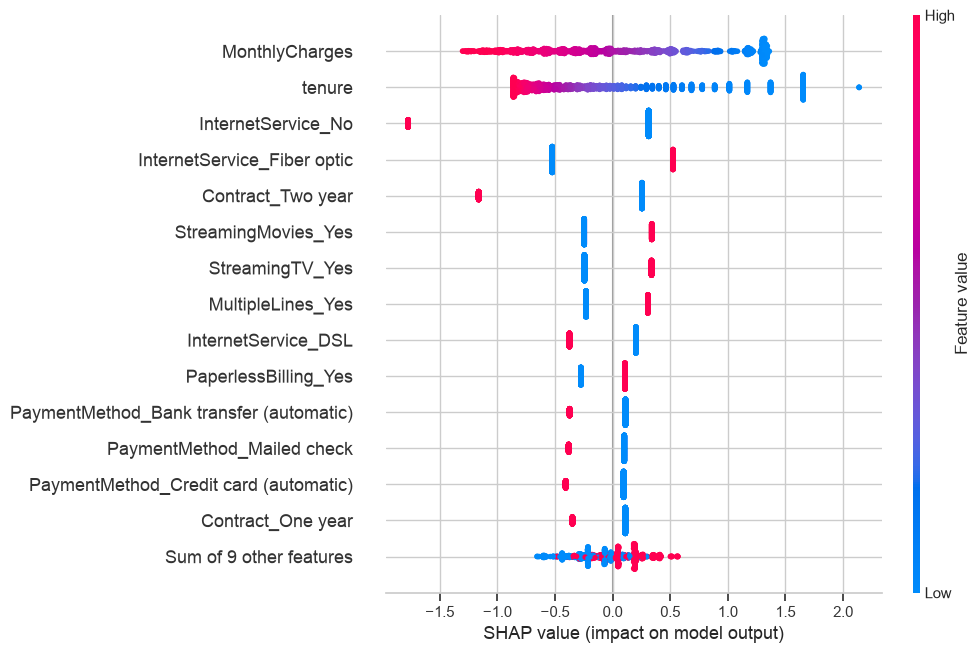

In [25]:
prep = final_pipe[:-1]
feat_names = final_pipe.named_steps['prep'].get_feature_names_out()
Xt_train = pd.DataFrame(prep.transform(X_train), columns=feat_names)
Xt_test = pd.DataFrame(prep.transform(X_test), columns=feat_names)

explainer = shap.LinearExplainer(final_pipe.named_steps['model'], shap.sample(Xt_train, 100, random_state=SEED))
sv = explainer(Xt_test)

# Show numeric features in original units on the plots
display_data = Xt_test.copy()
display_data[NUM_FINAL] = X_test[NUM_FINAL].values
sv_display = shap.Explanation(sv.values, sv.base_values, data=display_data.values, feature_names=list(feat_names))

shap.plots.beeswarm(sv_display, max_display=15)

One-hot encoding splits each categorical feature over several columns. Adding their SHAP values back together gives the importance of each original feature.

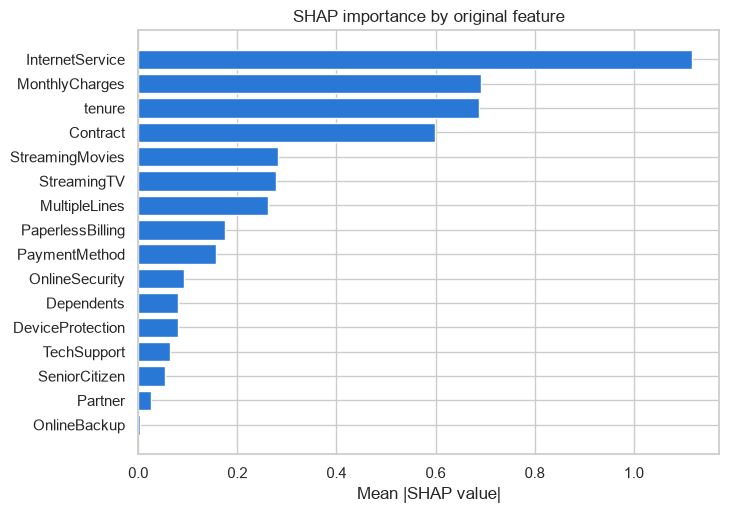

In [26]:
source = [next(c for c in NUM_FINAL + CAT_FINAL if f == c or f.startswith(c + '_')) for f in feat_names]
shap_grouped = pd.DataFrame(sv.values, columns=feat_names).T.groupby(source).sum().T
shap_importance = shap_grouped.abs().mean().sort_values()

plt.figure(figsize=(7.5, 5.5))
plt.barh(shap_importance.index, shap_importance.values, color=BLUE)
plt.xlabel('Mean |SHAP value|')
plt.title('SHAP importance by original feature')
plt.show()

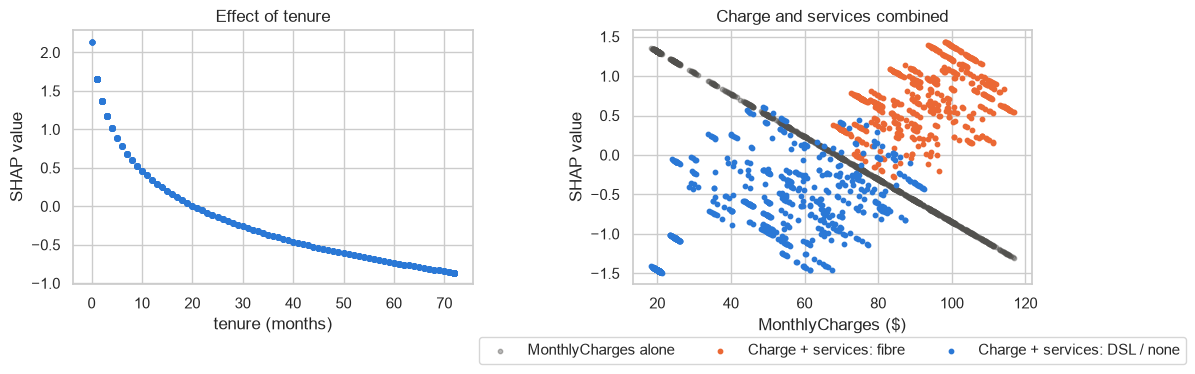

In [27]:
fiber = X_test['InternetService'].eq('Fiber optic').values
bundle = shap_grouped[[c for c in SERVICES if c in CAT_FINAL] + ['MonthlyCharges']].sum(axis=1).values

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(X_test['tenure'], sv.values[:, list(feat_names).index('tenure')], s=12, color=BLUE)
axes[0].set(xlabel='tenure (months)', ylabel='SHAP value', title='Effect of tenure')
axes[1].scatter(X_test['MonthlyCharges'], sv.values[:, list(feat_names).index('MonthlyCharges')], s=10,
                color=GREY, alpha=0.4, label='MonthlyCharges alone')
axes[1].scatter(X_test['MonthlyCharges'][fiber], bundle[fiber], s=10, color=ORANGE, label='Charge + services: fibre')
axes[1].scatter(X_test['MonthlyCharges'][~fiber], bundle[~fiber], s=10, color=BLUE, label='Charge + services: DSL / none')
axes[1].set(xlabel='MonthlyCharges ($)', ylabel='SHAP value', title='Charge and services combined')
axes[1].legend(loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=3)
plt.tight_layout()
plt.show()

- **Tenure:** risk is highest in the first months and falls steeply until about 20 months, then levels off. The first year is the critical window.
- **Contract:** a two-year contract strongly lowers risk, even with tenure held fixed.
- **Charges and services must be read together** (right plot). Services explain 99.9% of the bill, so on its own a higher charge *lowers* predicted risk (grey): it compares customers paying more for the *same* bundle. Combined with the services, **fibre-optic customers carry clearly higher risk**, which matches H2.
- **Electronic check** and **paperless billing** add moderate risk. **OnlineSecurity** and **TechSupport** lower it slightly.

**One customer explained:** the highest-risk customer in the test set.

Predicted churn probability: 0.93


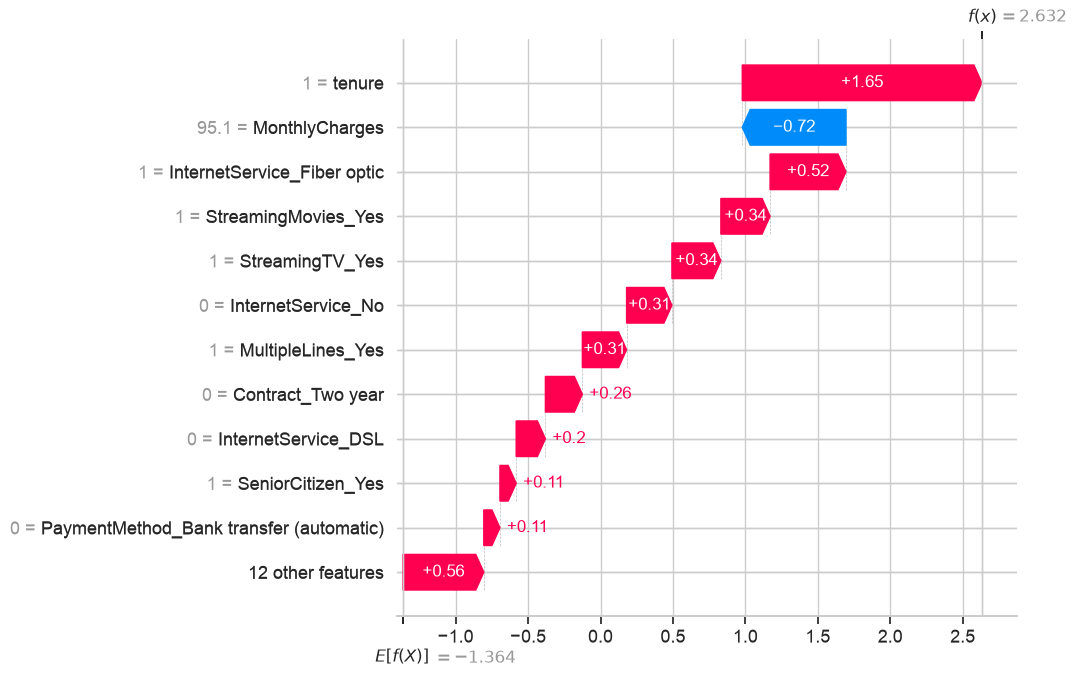

In [28]:
i = int(np.argmax(proba_test))
print(f'Predicted churn probability: {proba_test[i]:.2f}')
shap.plots.waterfall(sv_display[i], max_display=12)

### 10.2 Permutation importance (cross-check)
Permutation importance measures how much test PR-AUC drops when one feature is shuffled. It works differently from SHAP, so if the two agree, the explanation is more trustworthy.

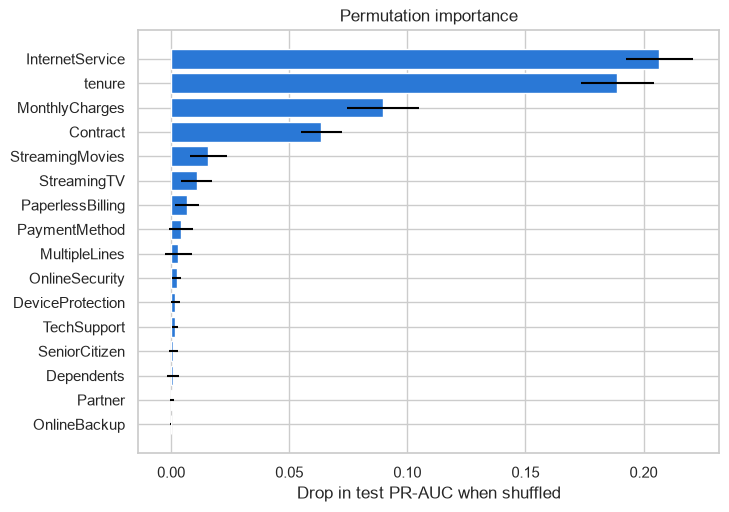

Rank agreement with SHAP: Spearman rho = 0.97


In [29]:
perm = permutation_importance(final_pipe, X_test, y_test, scoring='average_precision',
                              n_repeats=20, random_state=SEED, n_jobs=-1)
perm_df = pd.DataFrame({'mean': perm.importances_mean, 'std': perm.importances_std},
                       index=X_test.columns).loc[NUM_FINAL + CAT_FINAL].sort_values('mean')

plt.figure(figsize=(7.5, 5.5))
plt.barh(perm_df.index, perm_df['mean'], xerr=perm_df['std'], color=BLUE)
plt.xlabel('Drop in test PR-AUC when shuffled')
plt.title('Permutation importance')
plt.show()

print(f"Rank agreement with SHAP: Spearman rho = {stats.spearmanr(shap_importance[perm_df.index], perm_df['mean']).statistic:.2f}")

Both methods rank the features almost identically (ρ ≈ 0.95), with **InternetService, tenure, MonthlyCharges and Contract** well ahead of the rest.

## 11. Conclusions

**Model**
- Final model: **Logistic Regression** on 16 features with log(tenure). Test PR-AUC 0.66 (2.5× the no-skill baseline), ROC-AUC 0.85, well calibrated.
- It ties statistically with XGBoost, HistGB and Random Forest and significantly beats KNN. It was chosen for calibration, simplicity and interpretability.
- The most useful feature engineering step was putting tenure on a log scale.

**Who churns, and what to do**
1. **New customers:** risk is highest in the first months. Focus on onboarding during the first year.
2. **Month-to-month contracts:** the strongest lever. Offer incentives to move to one- or two-year contracts.
3. **Fibre-optic customers:** highest bills and highest churn. Look into fibre pricing and service quality.
4. **No security / tech support, electronic-check payment:** bundle protective services and encourage automatic payment.
5. **Targeting:** contact customers with predicted risk ≥ 0.22.

**Limitations**
- These are associations, not causal effects. Retention levers should be tested with an A/B test.
- The campaign figures are assumptions. Re-derive the threshold with real costs.
- The data is a single snapshot, so the model has not been tested on later time periods.